# Buildings on a Tile

Takes one random 256x256 tile and shows it three ways, side by side:
1. the image by itself
2. the image with the building footprints on top
3. the flood map (label) for the same tile

Needs the building file for the tile's quadkey in `data/buildings/` (run `python scripts/buildings.py`).

In [227]:
import glob
import gzip
import json
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Polygon
from rasterio.warp import transform, transform_bounds
from rasterio.windows import Window

sys.path.append("../scripts")
from dataset import DATA_DIR, TILE
from buildings import BUILDINGS_DIR, get_quadkey

## Pick a random tile

Picks a random image between `FIRST_IMAGE` and `LAST_IMAGE` and a random top-left pixel (`ROW`, `COL`)

In [ ]:
SEED = None
FIRST_IMAGE = 1
LAST_IMAGE = 25
MIN_BUILDINGS = 1
MAX_TRIES = 200

rng = random.Random(SEED)

## Read the tile and load its buildings

Each line of a building file is one GeoJSON building. We keep it only if its bounding box overlaps the tile's bounding box.
A polygon's `coordinates[0]` is its outer ring, a list of `[lon, lat]` points.
Some images are stored in meters (UTM) instead of lon/lat, so the tile box is converted to lon/lat to compare, and the building points are converted to the image's coordinates to draw.

In [229]:
for attempt in range(MAX_TRIES):
    # Random image and random tile position inside it
    IMAGE = rng.randint(FIRST_IMAGE, LAST_IMAGE)
    src = rasterio.open(DATA_DIR / f"image_{IMAGE}" / "image.tif")
    ROW = rng.randint(0, src.height - TILE)
    COL = rng.randint(0, src.width - TILE)

    window = Window(COL, ROW, TILE, TILE)
    rgb = src.read([1, 2, 3], window=window)   # (3, H, W)
    rgb = rgb.transpose(1, 2, 0)               # (H, W, 3) for imshow
    alpha = src.read(4, window=window)         # 0 where the image has no data
    west, south, east, north = src.window_bounds(window)   # in the image's own coordinates
    crs = src.crs
    src.close()

    # Same box in longitude/latitude, because the building files use lon/lat
    lon_w, lat_s, lon_e, lat_n = transform_bounds(crs, "EPSG:4326", west, south, east, north)

    # Flood label for the same window: 0 = dry, 1 = flood
    label_src = rasterio.open(DATA_DIR / f"image_{IMAGE}" / "label.tif")
    label = label_src.read(1, window=window).astype(np.int8)
    label_src.close()
    label[alpha == 0] = -1                     # no image data = unknown

    center_lon = (lon_w + lon_e) / 2
    center_lat = (lat_s + lat_n) / 2
    quadkey = get_quadkey(center_lon, center_lat)

    building_files = glob.glob(str(BUILDINGS_DIR / f"*_{quadkey}.csv.gz"))

    buildings = []   # each one is a list of [x, y] points in the image's coordinates
    for path in building_files:
        f = gzip.open(path, "rt")
        for line in f:
            feature = json.loads(line)
            geometry = feature["geometry"]
            if geometry["type"] != "Polygon":
                continue
            ring = geometry["coordinates"][0]

            lons = []
            lats = []
            for point in ring:
                lons.append(point[0])
                lats.append(point[1])

            # Skip if the building's box is completely outside the tile's box
            if max(lons) < lon_w or min(lons) > lon_e:
                continue
            if max(lats) < lat_s or min(lats) > lat_n:
                continue

            # Convert the points from lon/lat to the image's coordinates so they line up
            xs, ys = transform("EPSG:4326", crs, lons, lats)
            ring_in_image_coords = []
            for k in range(len(xs)):
                ring_in_image_coords.append([xs[k], ys[k]])
            buildings.append(ring_in_image_coords)
        f.close()

    if len(buildings) >= MIN_BUILDINGS:
        break
else:
    raise RuntimeError("No tile with buildings found. Did you download the building files?")

print(f"image {IMAGE}, row {ROW}, col {COL}, quadkey {quadkey}")
print(len(buildings), "buildings touch this tile")

image 24, row 217, col 26, quadkey 023113121
95 buildings touch this tile


## Draw it out

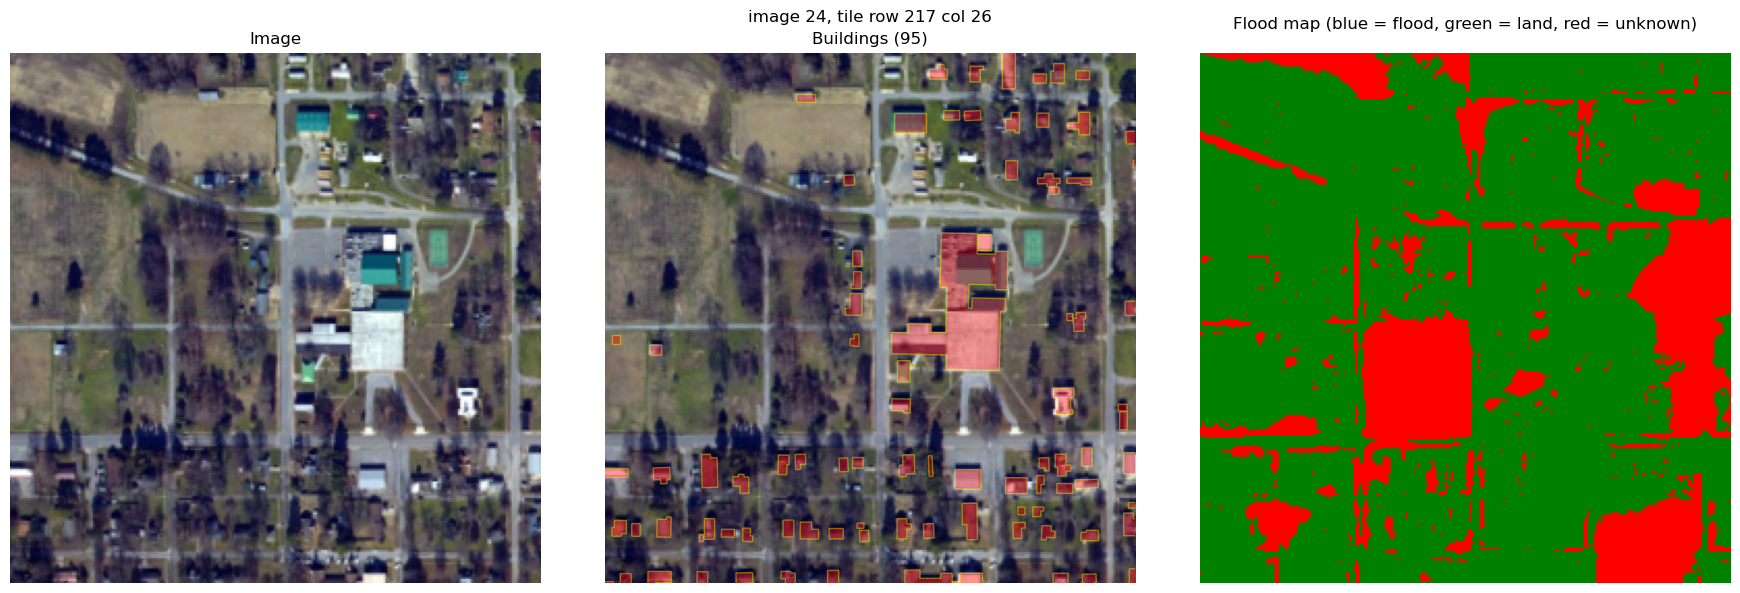

In [230]:
extent = (west, east, south, north)

# Flood map colors: 0 (land) = green, 1 (flood) = blue, unknown = red
cmap = ListedColormap(["green", "blue"])
cmap.set_bad("red")
label_masked = np.ma.masked_equal(label, -1)   # hides the -1 pixels so they get the "bad" color

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Image by itself
axes[0].imshow(rgb, extent=extent)
axes[0].set_title("Image")

# 2. Image with buildings
axes[1].imshow(rgb, extent=extent)
for ring in buildings:
    patch = Polygon(ring, closed=True, facecolor="red", edgecolor="yellow", alpha=0.4, lw=1)
    axes[1].add_patch(patch)
axes[1].set_title(f"Buildings ({len(buildings)})")

# 3. Flood map
axes[2].imshow(label_masked, cmap=cmap, vmin=0, vmax=1, extent=extent)
axes[2].set_title("Flood map (blue = flood, green = land, red = unknown)")

for ax in axes:
    # imshow can change the axis limits, so set them back to the tile
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.axis("off")   # no ticks or axis labels

fig.suptitle(f"image {IMAGE}, tile row {ROW} col {COL}")
plt.tight_layout()
plt.show()